# DNN Challenge 2: Santa_Claude final submission

This notebook follows the template: it **loads the data**, writes **our model** (`model.py`) and **our training**
(`train.py`), and **packages the three submission files** into `Santa_Claude.zip`. It finishes by running the
official checker and saving the trained weights as `Santa_Claude.pt`.

**Model: BandFormer (49,645 parameters).** Each of the 6 sub-bands is a stream with shared weights (d = 40). A
stream's input is the current 6 bits rotated so its own band comes first, plus a learned band embedding. The layers,
in order: GRU → causal self-attention over time (causal depthwise conv on q/k/v, **no positional encoding**: it
matches earlier slots on content alone, and the GRU and convolutions carry the order) → GELU MLP → attention across
the 6 sub-bands of the same slot → MLP → second causal self-attention over time → MLP. The output is a per-band busy
score, mapped onto the 64 tokens through the fixed bit table, plus a joint MLP correction over all 6 band states.

**Training:** AdamW (lr 9e-3, weight decay 0.15), 200-step warm-up then cosine decay over an 18-minute training
budget (compilation included), batch 32, full 1024-slot sequences, fp16 AMP, gradient clipping 1.0, EMA 0.999 (the
EMA weights are saved), `torch.compile` with fused AdamW for speed (falls back to normal mode automatically). Trains
on train + val.

**Result:** trained on `train.npz` only with the same settings (18 min on a Colab T4, 35.8 passes over the data),
val accuracy **81.42%** (cross-entropy 0.664). Round-1 model: 77.36%.

Run on Colab with Runtime → Change runtime type → **T4 GPU**, then run the cells top to bottom.

## 0. Setup

In [13]:
import os, sys, time, zipfile, importlib, subprocess
import numpy as np
import torch
import torch.nn.functional as F

DATA_DIR = "."               # folder containing train.npz, val.npz and check_submission.py
TEAM_NAME = "Santa_Claude"   # the submission is saved as f"{TEAM_NAME}.zip"
device = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device:", device,
      "|", torch.cuda.get_device_name() if device == "cuda" else "no GPU: training will be slow")
URL = "https://github.com/shashankvatedka/Deep-Learning-2026/releases/download/sequence_models/"
for f in ("train.npz", "val.npz", "check_submission.py"):
    path = os.path.join(DATA_DIR, f)
    if not os.path.exists(path):  # download the challenge files if they are not here yet
        subprocess.run(["wget", "-q", "-O", path, URL + f], check=True)
    print(f"{f:22s}", "found" if os.path.exists(path) else "MISSING")

torch 2.14.1+cu130 | device: cuda | Tesla T4
train.npz              found
val.npz                found
check_submission.py    found


## 1. The data

Each row of `x` is one sequence of **1024 tokens**. Token `x[i, t]` is the busy/idle state of 6 sub-bands at slot
`t`: bit `b` of the token is 1 if sub-band `b` was sensed busy. The task is to predict `x[i, t+1]` from
`x[i, :t+1]`. Targets `x[:, 32:]` are scored.

In [14]:
x_train = np.load(os.path.join(DATA_DIR, "train.npz"))["x"]
x_val = np.load(os.path.join(DATA_DIR, "val.npz"))["x"]
print("train:", x_train.shape, x_train.dtype, "| val:", x_val.shape, "| token range", x_train.min(), "-", x_train.max())

def bits(tok):
    # (..., ) uint8 tokens -> (..., 6) busy/idle bits, sub-band 0 first
    return (np.asarray(tok)[..., None] >> np.arange(6)) & 1

print("first tokens of sequence 0:", x_train[0, :8])
print("as bits (rows = slots, columns = sub-bands 0..5):")
print(bits(x_train[0, :8]))

train: (8000, 1024) uint8 | val: (1000, 1024) | token range 0 - 63
first tokens of sequence 0: [ 8  3 33 17 11 41  9 11]
as bits (rows = slots, columns = sub-bands 0..5):
[[0 0 0 1 0 0]
 [1 1 0 0 0 0]
 [1 0 0 0 0 1]
 [1 0 0 0 1 0]
 [1 1 0 1 0 0]
 [1 0 0 1 0 1]
 [1 0 0 1 0 0]
 [1 1 0 1 0 0]]


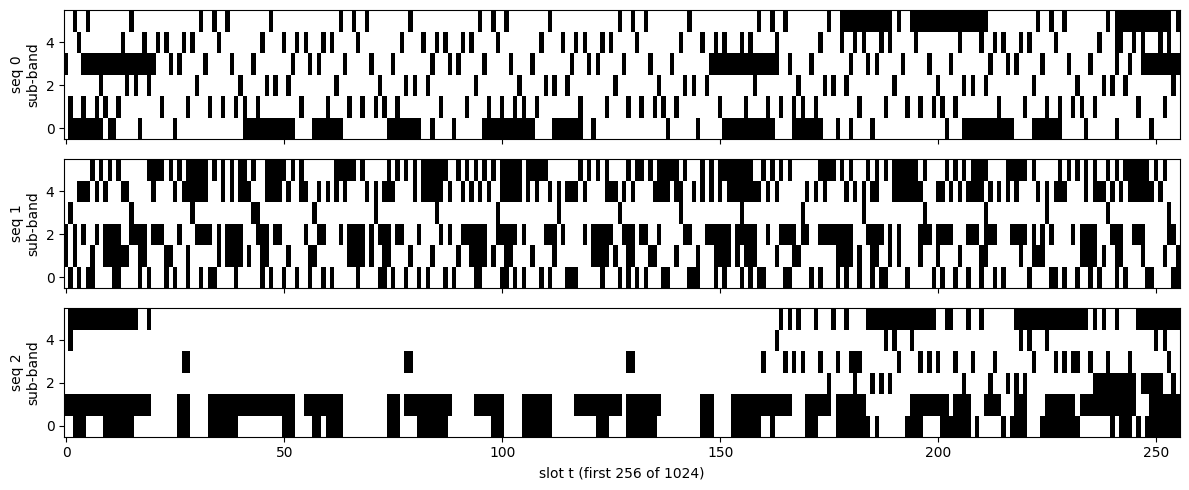

In [15]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(3, 1, figsize=(12, 5), sharex=True)
for ax, i in zip(axes, (0, 1, 2)):
    ax.imshow(bits(x_train[i, :256]).T, aspect="auto", cmap="Greys", interpolation="nearest", origin="lower")
    ax.set_ylabel(f"seq {i}\nsub-band")
axes[-1].set_xlabel("slot t (first 256 of 1024)")
plt.tight_layout(); plt.show()

In [16]:
# Two non-learned references on val (targets x[:, 32:])
persist = np.mean(x_val[:, 32:] == x_val[:, 31:-1])
print(f"repeat the last token:      {persist:.4f}")
print(f"always the most common token: {np.mean(x_val[:, 32:] == np.bincount(x_train.ravel()).argmax()):.4f}")

repeat the last token:      0.3026
always the most common token: 0.0540


## 2. OUR MODEL (`model.py`)

The next cell writes `model.py`. It defines **`build_model()`**, which returns an `nn.Module` with the required
interface: input `(B, L)` int64 tokens with L ≤ 1024, output `(B, L, 64)` float32 logits, where `out[:, t]` scores
the token at slot `t + 1`.

- **Imports:** only `torch`.
- **Fixed tables:** the token → bits unpacking table and the band rotation index are built from formulas in
  `__init__` and registered with `persistent=False`, so they are free and do not depend on the seed. (The RoPE code
  path is kept as an option but is off: `rope=False`.)
- **Causality:** the GRU, the time attentions (`is_causal=True`) and the left-padded convolutions only look back;
  the band attention mixes the 6 sub-bands of the *same* slot only.

In [17]:
%%writefile model.py
"""BandFormer: causal next-slot spectrum-occupancy model (DNN Challenge 2).

Each of the 6 sub-bands is modelled as its own stream with shared weights (the streams are stacked in the batch
dimension). Per stream: GRU -> causal self-attention over time -> MLP; then the 6 streams of each slot exchange
information through attention across sub-bands -> MLP; then a second causal self-attention over time -> MLP.
Output: one busy score per sub-band, mapped onto the 64 tokens through the fixed bit table (log-linear part), plus
a learned joint correction from an MLP over all 6 band states (captures correlations between sub-bands).

Course building blocks only (linear layers, GELU MLPs, LayerNorm, residual connections, GRU, causal multi-head
attention, optionally with RoPE, causal depthwise convolution). The only fixed tables are the token->bits unpacking,
the band rotation index and the RoPE cos/sin (when used), all built from formulas in __init__ as non-persistent buffers.
"""
import torch
import torch.nn as nn
import torch.nn.functional as F

NB = 6          # sub-bands
VOCAB = 64      # 2 ** NB tokens
MAX_LEN = 1024

# d: width of every stream. heads: heads of the two time attentions (head size d / heads). rope: rotary positions
# in the time attentions (False = they match on content alone; the GRU and the causal convolutions carry the order).
# joint_hidden: width of the joint output MLP. mult: MLP expansion (0 = no MLPs).
CONFIG = {'d': 40, 'heads': 1, 'rope': False, 'joint_hidden': 28, 'mult': 1}  # @@CONFIG@@


class CausalDWConv(nn.Module):
    """Depthwise 1-D convolution over time, left-padded: position t sees t-k+1 .. t. (N, L, C) -> (N, L, C)."""

    def __init__(self, c, k):
        super().__init__()
        self.k = k
        self.conv = nn.Conv1d(c, c, k, groups=c)

    def forward(self, x):
        y = self.conv(F.pad(x.transpose(1, 2), (self.k - 1, 0)))
        return y.transpose(1, 2).contiguous()  # contiguous: keeps attention on the fast GPU kernel


class TimeAttention(nn.Module):
    """Causal multi-head self-attention over time with a causal depthwise conv on q/k/v (Primer-style), so a key
    summarises the last few slots and a head can find 'the earlier slots that looked like now' and read what
    followed them. rope=True adds rotary positions (RoPE) to q and k."""

    def __init__(self, d, heads, conv_k=3, rope=True):
        super().__init__()
        self.h, self.hd = heads, d // heads
        self.qkv = nn.Linear(d, 3 * d, bias=False)
        self.qconv = CausalDWConv(3 * d, conv_k)
        self.out = nn.Linear(d, d, bias=False)
        self.rope = rope
        if rope:
            half = self.hd // 2
            inv = 1.0 / (10000.0 ** (torch.arange(half, dtype=torch.float64) / half))
            ang = torch.arange(MAX_LEN, dtype=torch.float64).unsqueeze(1) * inv
            self.register_buffer("cos", ang.cos().to(torch.get_default_dtype()), persistent=False)
            self.register_buffer("sin", ang.sin().to(torch.get_default_dtype()), persistent=False)

    def _rope(self, t):
        L = t.shape[2]
        c, s = self.cos[:L].to(t.dtype), self.sin[:L].to(t.dtype)
        a, b = t[..., 0::2], t[..., 1::2]
        return torch.stack((a * c - b * s, a * s + b * c), -1).flatten(-2)

    def forward(self, x):
        N, L, _ = x.shape
        q, k, v = self.qconv(self.qkv(x)).view(N, L, 3, self.h, self.hd).permute(2, 0, 3, 1, 4)
        if self.rope:
            q, k = self._rope(q), self._rope(k)
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        return self.out(y.transpose(1, 2).reshape(N, L, -1))


class BandAttention(nn.Module):
    """Multi-head self-attention across the 6 sub-bands of the same slot (no time mixing, hence causal).
    Written out explicitly: the attention matrices are only 6 x 6, and the generic attention kernel is slow for
    hundreds of thousands of such tiny problems."""

    def __init__(self, d, heads):
        super().__init__()
        self.h, self.hd = heads, d // heads
        self.qkv = nn.Linear(d, 3 * d, bias=False)
        self.out = nn.Linear(d, d, bias=False)

    def forward(self, x):  # (N, 6, d)
        N, S, _ = x.shape
        q, k, v = self.qkv(x).view(N, S, 3, self.h, self.hd).permute(2, 0, 3, 1, 4)   # each (N, h, 6, hd)
        att = torch.softmax((q @ k.transpose(-1, -2)) * self.hd ** -0.5, dim=-1)       # (N, h, 6, 6)
        return self.out((att @ v).transpose(1, 2).reshape(N, S, -1))


class MLP(nn.Module):
    """Pre-LayerNorm GELU MLP."""

    def __init__(self, d, mult):
        super().__init__()
        self.norm = nn.LayerNorm(d)
        self.fc1 = nn.Linear(d, mult * d)
        self.fc2 = nn.Linear(mult * d, d)

    def forward(self, x):
        return self.fc2(F.gelu(self.fc1(self.norm(x))))



class BandFormer(nn.Module):
    def __init__(self, d=32, heads=2, rope=True, joint_hidden=64, mult=2, mix_heads=2, conv_k=3):
        super().__init__()
        self.d = d
        # fixed re-encodings of the current token (free: formula-built, non-persistent)
        tok = torch.arange(VOCAB).unsqueeze(1)
        self.register_buffer("bits", ((tok >> torch.arange(NB)) & 1).to(torch.get_default_dtype()), persistent=False)
        rot = (torch.arange(NB)[:, None] + torch.arange(NB)[None, :]) % NB  # stream b sees bands b, b+1, ... (mod 6)
        self.register_buffer("rot", rot, persistent=False)
        # input: the current 6 bits rotated so the stream's own band comes first, plus a learned band identity
        self.inp = nn.Linear(NB, d)
        self.band_emb = nn.Parameter(torch.zeros(NB, d))
        nn.init.normal_(self.band_emb, std=0.1)
        # per-band temporal stack (weights shared by the 6 streams)
        self.gru_n, self.gru = nn.LayerNorm(d), nn.GRU(d, d, batch_first=True)
        self.att1_n, self.att1 = nn.LayerNorm(d), TimeAttention(d, heads, conv_k, rope)
        self.mlp1 = MLP(d, mult) if mult else None
        # exchange between the 6 sub-bands of each slot
        self.mix_n, self.mix = nn.LayerNorm(d), BandAttention(d, mix_heads)
        self.mlp2 = MLP(d, mult) if mult else None
        # second temporal layer, now aware of the other bands (hoppers, contention)
        self.att2_n, self.att2 = nn.LayerNorm(d), TimeAttention(d, heads, conv_k, rope)
        self.mlp3 = MLP(d, mult) if mult else None
        # output: per-band busy scores + joint 64-way correction
        self.norm_f = nn.LayerNorm(d)
        self.band_head = nn.Linear(d, 1)
        self.joint1 = nn.Linear(NB * d, joint_hidden)
        self.joint2 = nn.Linear(joint_hidden, VOCAB)
        nn.init.zeros_(self.joint2.weight)
        nn.init.zeros_(self.joint2.bias)

    def forward(self, x):  # x: (B, L) int64 -> (B, L, 64) logits for the next slot
        B, L = x.shape
        d = self.d
        dt = self.inp.weight.dtype
        bits = self.bits.to(dt)[x]                                           # (B, L, 6)
        h = self.inp(bits[..., self.rot]) + self.band_emb                    # (B, L, 6 streams, d)
        h = h.permute(0, 2, 1, 3).reshape(B * NB, L, d)                      # one stream per (sequence, band)
        h = h + self.gru(self.gru_n(h))[0]
        h = h + self.att1(self.att1_n(h))
        if self.mlp1 is not None:
            h = h + self.mlp1(h)
        h = h.view(B, NB, L, d).transpose(1, 2).reshape(B * L, NB, d)        # group the 6 bands of each slot
        h = h + self.mix(self.mix_n(h))
        if self.mlp2 is not None:
            h = h + self.mlp2(h)
        h = h.view(B, L, NB, d).transpose(1, 2).reshape(B * NB, L, d)
        h = h + self.att2(self.att2_n(h))
        if self.mlp3 is not None:
            h = h + self.mlp3(h)
        h = self.norm_f(h).view(B, NB, L, d).transpose(1, 2)                 # (B, L, 6, d)
        s = self.band_head(h).squeeze(-1)                                    # (B, L, 6) per-band busy scores
        logits = s @ self.bits.to(dt).t()                                    # independent-bands part
        return logits + self.joint2(F.gelu(self.joint1(h.reshape(B, L, NB * d))))


def build_model():
    return BandFormer(**CONFIG)


Overwriting model.py


In [18]:
import model as model_py
importlib.reload(model_py)                     # pick up edits to model.py

def n_params(m):
    # the checker's count: every tensor in the state_dict (except BatchNorm's num_batches_tracked)
    return sum(v.numel() for k, v in m.state_dict().items() if not k.endswith("num_batches_tracked"))

@torch.no_grad()
def quick_causality_check(m, L=256, p=100):
    # changing token p must not change any output before p (the checker does a stricter version)
    m = m.eval()
    x = torch.from_numpy(x_val[:2, :L].astype(np.int64))
    x2 = x.clone(); x2[:, p] = (x2[:, p] + 1) % 64
    a, b = m(x), m(x2)
    assert a.shape == (2, L, 64), f"output shape {tuple(a.shape)}, expected (2, {L}, 64)"
    return (a[:, :p] - b[:, :p]).abs().max().item()

m = model_py.build_model()
n = n_params(m)
print(f"parameters: {n:,} / 50,000", "OK" if n <= 50_000 else "OVER BUDGET")
print(f"max change of outputs before the perturbed token: {quick_causality_check(m):.1e} (should be ~0)")

parameters: 49,645 / 50,000 OK
max change of outputs before the perturbed token: 0.0e+00 (should be ~0)


## 3. OUR TRAINING (`train.py`)

The next cell writes `train.py`, and the cell after it runs it. The defaults are the submitted configuration, so a
plain `python train.py` (what the organisers rerun on a Colab T4, with `train.npz` and `val.npz` in the working
directory) reproduces `weights.pt`:
- trains on **train + val**, full sequences with teacher forcing (input `x[:, :-1]`, target `x[:, 1:]`, 64-way
  cross-entropy at every position);
- **time-budgeted:** the cosine schedule follows elapsed training time and stops at 18 minutes (compilation
  included), so the run stays under the 20-minute limit on any T4; the number of steps depends slightly on the GPU's
  speed, so a rerun matches up to seed-level noise;
- `torch.compile` (training only), fused AdamW and a single-kernel EMA update make each step cheaper, so more passes
  fit in the budget; the model and the saved weights are plain PyTorch;
- saves the EMA weights to `weights.pt`.

`python train.py --holdout` trains on `train.npz` only and reports accuracy on `val.npz`: this gave the 81.42%
quoted above.

In [19]:
%%writefile train.py
# Trains build_model() from model.py and writes weights.pt.
#   Submission run (train.npz + val.npz):   python train.py
#   Honest evaluation (train.npz only):     python train.py --holdout     (reports accuracy on val.npz)
#
# The model is small (d = 40), so a training step is limited by the number of GPU kernel launches and memory
# passes, not by arithmetic. This script therefore makes each step cheaper, so more epochs fit in the time limit:
#   * torch.compile fuses the many small element-wise ops into a few kernels (training only; model.py and the
#     saved weights are plain PyTorch). If compilation fails, training falls back to eager mode automatically;
#   * fused AdamW (one kernel for all parameters) and a foreach EMA update (one kernel for all EMA weights);
#   * no CPU-GPU synchronisation inside the loop (the loss is read only when a log line is printed).
# Training is time-budgeted: the cosine schedule follows elapsed training time (compilation included, evaluation
# excluded), so the run ends inside --minutes on whatever T4 runs it.
# Optional length curriculum: for the first --crop-frac of the time, train on random crops of --crop-len slots
# (cheaper steps, so more optimiser updates), then on full 1024-slot sequences.
import argparse
import copy
import math
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from model import build_model

T0 = 32                     # targets x[:, 32:] are scored
N_FINAL = 9000              # sequences in train + val; progress is reported in passes over 9,000 sequences
DEFAULT_COMPILE = "default"    # @@COMPILE@@  one of: none, default, reduce-overhead (set by the notebook benchmark)


def show(msg):
    """Lines for the person start with '» '; the notebook prints only these (plus RESULT/BENCH/DONE summaries)."""
    print("» " + msg, flush=True)


@torch.no_grad()
def evaluate(model, x, device, bs=32):
    model.eval()
    hit = nll = n = 0.0
    for i in range(0, len(x), bs):
        xb = x[i:i + bs].to(device)
        lg = model(xb)[:, T0 - 1:-1].float()
        y = xb[:, T0:]
        hit += (lg.argmax(-1) == y).sum().item()
        nll += F.cross_entropy(lg.reshape(-1, 64), y.reshape(-1), reduction="sum").item()
        n += y.numel()
    return hit / n, nll / n


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--data-dir", default=".")
    ap.add_argument("--holdout", action="store_true", help="train on train.npz only and report val.npz")
    ap.add_argument("--minutes", type=float, default=18.0, help="training-time budget, compilation included")
    ap.add_argument("--compile", default=DEFAULT_COMPILE, choices=["none", "default", "reduce-overhead"])
    ap.add_argument("--bs", type=int, default=32)
    ap.add_argument("--lr", type=float, default=0.009)
    ap.add_argument("--wd", type=float, default=0.15)
    ap.add_argument("--warmup-steps", type=int, default=200, help="linear warm-up, counted in optimiser steps")
    ap.add_argument("--ema", type=float, default=0.999)
    ap.add_argument("--crop-len", type=int, default=0, help="length of the random crops of the first phase (0 = off)")
    ap.add_argument("--crop-frac", type=float, default=0.0, help="fraction of the time budget spent on crops")
    ap.add_argument("--eval-every", type=float, default=0, help="with --holdout: minutes between quick evals")
    ap.add_argument("--log-every", type=float, default=60, help="seconds between progress rows")
    ap.add_argument("--bench", type=int, default=0, help="only time this many steps, then exit (no saving)")
    ap.add_argument("--seed", type=int, default=0)
    ap.add_argument("--out", default="weights.pt")
    a = ap.parse_args()

    torch.manual_seed(a.seed)
    np.random.seed(a.seed)
    device = "cuda" if torch.cuda.is_available() else "cpu"
    cuda = device == "cuda"
    if cuda:
        torch.backends.cudnn.benchmark = True   # fixed shapes: let cuDNN pick its fastest GRU / conv kernels

    # ---- data (loading is excluded from the time limit) ----
    xtr = torch.from_numpy(np.load(f"{a.data_dir}/train.npz")["x"].astype(np.int64))
    xva = torch.from_numpy(np.load(f"{a.data_dir}/val.npz")["x"].astype(np.int64))
    if not a.holdout:
        xtr = torch.cat((xtr, xva))
    xtr = xtr.to(device)
    n_seq, seq_len = xtr.shape
    crop_on = 0 < a.crop_len < seq_len and a.crop_frac > 0

    # ---- model, EMA copy, optimiser ----
    model = build_model().to(device)
    n_par = sum(v.numel() for v in model.state_dict().values())
    print(f"[setup] parameters {n_par:,} | sequences {n_seq} | device {device} | budget {a.minutes} min | "
          f"compile {a.compile} | lr {a.lr} wd {a.wd} bs {a.bs} | crops {a.crop_len if crop_on else 'off'}"
          f"{' for ' + str(a.crop_frac) + ' of the time' if crop_on else ''}", flush=True)
    assert n_par <= 50_000, "parameter budget exceeded"
    ema = copy.deepcopy(model).eval()
    for p in ema.parameters():
        p.requires_grad_(False)
    for m in list(model.modules()) + list(ema.modules()):
        if isinstance(m, nn.RNNBase):
            m.flatten_parameters()
    model_params = list(model.parameters())
    ema_params = list(ema.parameters())

    decay = [p for n, p in model.named_parameters() if p.dim() >= 2 and "emb" not in n]
    other = [p for n, p in model.named_parameters() if not (p.dim() >= 2 and "emb" not in n)]
    groups = [{"params": decay, "weight_decay": a.wd}, {"params": other, "weight_decay": 0.0}]
    try:
        opt = torch.optim.AdamW(groups, lr=a.lr, betas=(0.9, 0.98), eps=1e-8, fused=cuda)
    except (RuntimeError, TypeError) as e:
        print(f"[setup] fused AdamW unavailable ({e}); using the default implementation", flush=True)
        opt = torch.optim.AdamW(groups, lr=a.lr, betas=(0.9, 0.98), eps=1e-8)
    scaler = torch.amp.GradScaler("cuda", enabled=cuda)

    train_model = model
    if a.compile != "none":
        try:
            train_model = torch.compile(model, mode=a.compile)
        except Exception as e:
            show(f"⚠️  speed-up (torch.compile) unavailable here, training in normal mode ({type(e).__name__})")
            train_model = model

    def lr_at(p, step):  # step-based linear warm-up x time-based cosine decay to 0
        return a.lr * min(1.0, (step + 1) / a.warmup_steps) * 0.5 * (1 + math.cos(math.pi * min(1.0, p)))

    def forward_loss(net, xb):
        with torch.autocast("cuda", dtype=torch.float16, enabled=cuda):
            lg = net(xb[:, :-1])
        return F.cross_entropy(lg.float().reshape(-1, 64), xb[:, 1:].reshape(-1))

    def train_step(xb, lr, dcy):
        nonlocal train_model
        for pg in opt.param_groups:
            pg["lr"] = lr
        if train_model is not model:
            try:
                if a.compile == "reduce-overhead":
                    torch.compiler.cudagraph_mark_step_begin()
                loss = forward_loss(train_model, xb)
            except Exception as e:  # compilation problem (first step or a new input length): continue uncompiled
                show(f"⚠️  speed-up (torch.compile) failed, training in normal mode ({type(e).__name__})")
                print(f"[warn ] compile error: {str(e)[:300]}", flush=True)
                train_model = model
                loss = forward_loss(model, xb)
        else:
            loss = forward_loss(model, xb)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model_params, 1.0)
        scaler.step(opt)
        scaler.update()
        with torch.no_grad():
            torch._foreach_lerp_(ema_params, model_params, 1.0 - dcy)
        return loss.detach()

    # ---- batches: shuffled passes over the data, without replacement, built on the GPU ----
    gen = torch.Generator(device=device).manual_seed(a.seed)
    cgen = torch.Generator().manual_seed(a.seed)     # crop offsets
    perm, ptr = torch.randperm(n_seq, device=device, generator=gen), 0

    budget = a.minutes * 60.0
    train_time, step, seen = 0.0, 0, 0
    loss_acc, loss_n, last_log = torch.zeros((), device=device), 0, 0.0
    next_eval = a.eval_every * 60.0 if (a.eval_every and a.holdout) else None
    if not a.bench:
        show(f"{'min':>5s} {'passes':>6s} {'len':>5s} {'loss':>7s}" + (f" {'val acc':>8s}" if next_eval else ""))
    bench_marks = {}
    seg_start = time.time()
    while True:
        elapsed = train_time + (time.time() - seg_start)
        if (a.bench and step >= a.bench) or (not a.bench and elapsed >= budget):
            break
        if ptr + a.bs > n_seq:
            perm, ptr = torch.randperm(n_seq, device=device, generator=gen), 0
        xb = xtr[perm[ptr:ptr + a.bs]]
        ptr += a.bs
        cur_len = seq_len
        if crop_on and not a.bench and elapsed < a.crop_frac * budget:
            cur_len = a.crop_len
            o = int(torch.randint(0, seq_len - cur_len + 1, (1,), generator=cgen))
            xb = xb[:, o:o + cur_len]
        lr = lr_at(elapsed / budget, step)
        dcy = min(a.ema, (1 + step) / (10 + step))
        loss = train_step(xb, lr, dcy)
        step += 1
        seen += a.bs
        loss_acc += loss
        loss_n += 1

        if a.bench:
            if step in (10, a.bench):
                if cuda:
                    torch.cuda.synchronize()
                bench_marks[step] = time.time() - seg_start
            continue
        now = train_time + (time.time() - seg_start)
        if now - last_log >= a.log_every:
            row = f"{now / 60:5.1f} {seen / N_FINAL:6.1f} {cur_len:5d} {(loss_acc / loss_n).item():7.3f}"
            if next_eval is not None and now >= next_eval:
                if cuda:
                    torch.cuda.synchronize()
                train_time += time.time() - seg_start          # pause the training clock during the check
                acc, _ = evaluate(ema, xva[:300], device)
                row += f" {acc * 100:7.1f}%"
                while next_eval <= now:
                    next_eval += a.eval_every * 60.0
                seg_start = time.time()
            show(row)
            last_log, loss_acc, loss_n = now, torch.zeros((), device=device), 0

    if a.bench:
        first10 = bench_marks.get(10, 0.0)
        ms = (bench_marks[a.bench] - first10) / max(1, a.bench - 10) * 1000
        print(f"BENCH compile={a.compile} first10_s={first10:.2f} ms_per_step={ms:.2f} "
              f"eager_fallback={int(train_model is model and a.compile != 'none')}", flush=True)
        return

    if cuda:
        torch.cuda.synchronize()
    train_time += time.time() - seg_start
    torch.save({k: v.detach().cpu().float() for k, v in ema.state_dict().items()}, a.out)
    print(f"DONE minutes={train_time / 60:.2f} passes={seen / N_FINAL:.2f} steps={step} "
          f"compiled={int(train_model is not model)} out={a.out}", flush=True)
    if a.holdout:
        acc, ce = evaluate(ema, xva, device)
        print(f"RESULT acc={acc:.6f} ce={ce:.6f} steps={step} passes={seen / N_FINAL:.3f} "
              f"minutes={train_time / 60:.3f}", flush=True)


if __name__ == "__main__":
    main()


Overwriting train.py


In [20]:
t = time.time()
!{sys.executable} train.py --data-dir {DATA_DIR}
print(f"wall time {(time.time() - t) / 60:.1f} min (limit: 20 min on a Colab T4)")

[setup] parameters 49,645 | sequences 9000 | device cuda | budget 18.0 min | compile default | lr 0.009 wd 0.15 bs 32 | crops off
»   min passes   len    loss
»   1.0    1.6  1024   1.686
»   2.0    3.6  1024   0.911
»   3.0    5.5  1024   0.823
»   4.0    7.5  1024   0.780
»   5.0    9.4  1024   0.757
»   6.0   11.4  1024   0.746
»   7.0   13.3  1024   0.737
»   8.0   15.3  1024   0.726
»   9.0   17.2  1024   0.718
»  10.0   19.1  1024   0.714
»  11.0   21.1  1024   0.705
»  12.0   23.0  1024   0.699
»  13.0   25.0  1024   0.690
»  14.0   26.9  1024   0.685
»  15.0   28.9  1024   0.678
»  16.0   30.8  1024   0.675
»  17.0   32.7  1024   0.669
DONE minutes=18.01 passes=34.65 steps=9744 compiled=1 out=weights.pt
wall time 18.2 min (limit: 20 min on a Colab T4)


## 4. Look at our model

Accuracy as a function of the slot shows how much the model learns *within* a sequence: early slots have little
history to go on. Accuracy is then split by sub-band, as the fraction of slots where the bit is predicted correctly.
Note: `weights.pt` was trained on train + val, so the val numbers here are optimistic; the honest val accuracy is
the `--holdout` result (81.42%).

val accuracy 0.8197  (repeat-last-token 0.3026)
per-sub-band bit accuracy: [0.967 0.962 0.96  0.961 0.959 0.962]


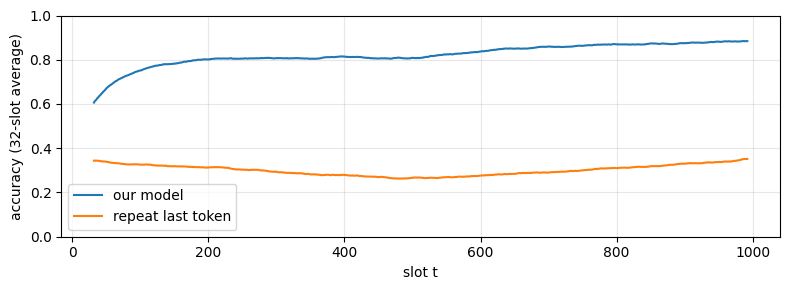

In [24]:
importlib.reload(model_py)
m = model_py.build_model()
m.load_state_dict(torch.load("weights.pt", map_location="cpu", weights_only=True))
m = m.to(device).eval()

with torch.no_grad():
    pred = np.concatenate([m(torch.from_numpy(x_val[i:i + 64].astype(np.int64)).to(device)).argmax(-1).cpu().numpy()
                           for i in range(0, len(x_val), 64)])
hit = pred[:, 31:-1] == x_val[:, 32:]
print(f"val accuracy {hit.mean():.4f}  (repeat-last-token {persist:.4f})")
print("per-sub-band bit accuracy:", np.round((bits(pred[:, 31:-1]) == bits(x_val[:, 32:])).mean((0, 1)), 3))

w = 32
curve = hit.mean(0)
plt.figure(figsize=(8, 3))
plt.plot(np.arange(32, 1024 - w + 1), np.convolve(curve, np.ones(w) / w, "valid"), label="our model")
plt.plot(np.arange(32, 1024 - w + 1), np.convolve((x_val[:, 32:] == x_val[:, 31:-1]).mean(0), np.ones(w) / w, "valid"),
         label="repeat last token")
plt.xlabel("slot t"); plt.ylabel(f"accuracy ({w}-slot average)"); plt.ylim(0, 1); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 5. Package and check

This zips `model.py`, `weights.pt` and `train.py` into `Santa_Claude.zip` (nothing else may be in it) and runs the official checker on it,
which takes a minute or two on CPU. **Submit the zip only if the checker prints `PASS`.** Warnings do not reject
a submission, but the organisers read the code behind each one.

In [25]:
zip_name = f"{TEAM_NAME}.zip"
with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as z:
    for f in ("model.py", "weights.pt", "train.py"):
        z.write(f)
print(f"{zip_name}: {os.path.getsize(zip_name) / 2**20:.2f} MB")
!{sys.executable} {os.path.join(DATA_DIR, "check_submission.py")} {zip_name} --val {os.path.join(DATA_DIR, "val.npz")}

Santa_Claude.zip: 0.19 MB
checking Santa_Claude.zip
  ok    zip size 0.19 MB (limit 5 MB)
  ok    zip contains model.py, weights.pt, train.py
  ok    model.py imports and calls are allowed (abc, collections, dataclasses, enum, functools, itertools, math, numbers, numpy, torch, typing)
  ok    build_model() + load_state_dict(strict=True)
  info  non-persistent float buffers, free if built from a formula in __init__ (384 values): bits 384
  ok    parameters 49,645 (limit 50,000; every tensor in weights.pt)
  ok    output float32 (4, 1024, 64), finite
  ok    deterministic in eval mode (max diff 0.0e+00)
  ok    causality and batch tests run in float64
  ok    causal: changing token p changes no output before p (max diff 0.0e+00)
  ok    prefix-consistent: outputs on x[:, :L] match the full run (max diff 6.8e-14)
  ok    batch-independent: alone vs in batches of 4 and 16 (max diff 0.0e+00)
  ok    weight sharing: every parametric module is called once per forward or once per time step

va

## 6. Trained weights as `Santa_Claude.pt`
Copies `weights.pt` (a state_dict for `build_model()` in `model.py`, loaded with `strict=True`) to `Santa_Claude.pt`
and downloads it, together with the zip.

In [26]:
import shutil
shutil.copy("weights.pt", f"{TEAM_NAME}.pt")
sd = torch.load(f"{TEAM_NAME}.pt", map_location="cpu", weights_only=True)
print(f"{TEAM_NAME}.pt: {sum(v.numel() for v in sd.values()):,} parameters, {os.path.getsize(f'{TEAM_NAME}.pt') / 1e3:.0f} KB")
try:
    from google.colab import files
    for f in (f"{TEAM_NAME}.pt", f"{TEAM_NAME}.zip"):
        files.download(f)
except ImportError:
    print("Not on Colab: the files are in the working directory.")

Santa_Claude.pt: 49,645 parameters, 212 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>